In [1]:
# from per.dataaccess import Crawling
# from per.dataaccess import Creating
import os
import matplotlib.pyplot as plt
import numpy as np
# from ultralytics import YOLO
# import yaml
# import torch
# from PIL import Image, ImageDraw, ImageFont
from sklearn.utils import shuffle
import cv2

In [2]:
def load_data() :
    DIRECTORY = os.getcwd() + "/dataset/"
    CATEGORY = ["train", "val"]
    output = []
    for category in CATEGORY:
        path = os.path.join(DIRECTORY, category)
        images = []
        labels = []

        print("Loading {}".format(category))

        for folder in os.listdir(path):
            label = class_names_label[folder]

            for file in os.listdir(os.path.join(path, folder)):
                #Lấy đường dẫn tới từng ảnh
                img_path = os.path.join(os.path.join(path, folder), file)

                #Đọc ảnh và resize ảnh
                image = cv2.imread(img_path)
                image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)#convert từ BGR qua RGB cho đúng màu
                image = cv2.resize(image, IMAGE_SIZE)

                #Thêm ảnh và label cho ảnh
                images.append(image)
                labels.append(label)
        #chuyển sang dạng numpy array, image là float32 và label là int32
        images = np.array(images, dtype = 'float32')
        labels = np.array(labels, dtype = 'int32')
        #ảnh sẽ có label tương ứng
        output.append((images, labels))
    return output
def display_examples(class_names, images, labels):
    """
        Hiển thị 25 ảnh từ mảng images và nhãn tương ứng
    """
    figsize = (20, 20)
    fig = plt.figure(figsize=figsize)
    fig.suptitle("Images from dataset", fontsize=16)
    for i in range(25):
        plt.subplot(5, 5, i+1) #vẽ nhiều biểu đồ trong 1 fig
        plt.xticks([])
        plt.yticks([])
        plt.grid(False)
        #image = cv2.resize(images[i], figsize)
        plt.imshow(images[i].astype(np.uint8))
        plt.xlabel(class_names[labels[i]])
    plt.show()

{'Information': 0, 'Mandatory': 1, 'Prohibition': 2, 'RE': 3, 'Supplementary': 4, 'Warning': 5}
Loading train
Loading val


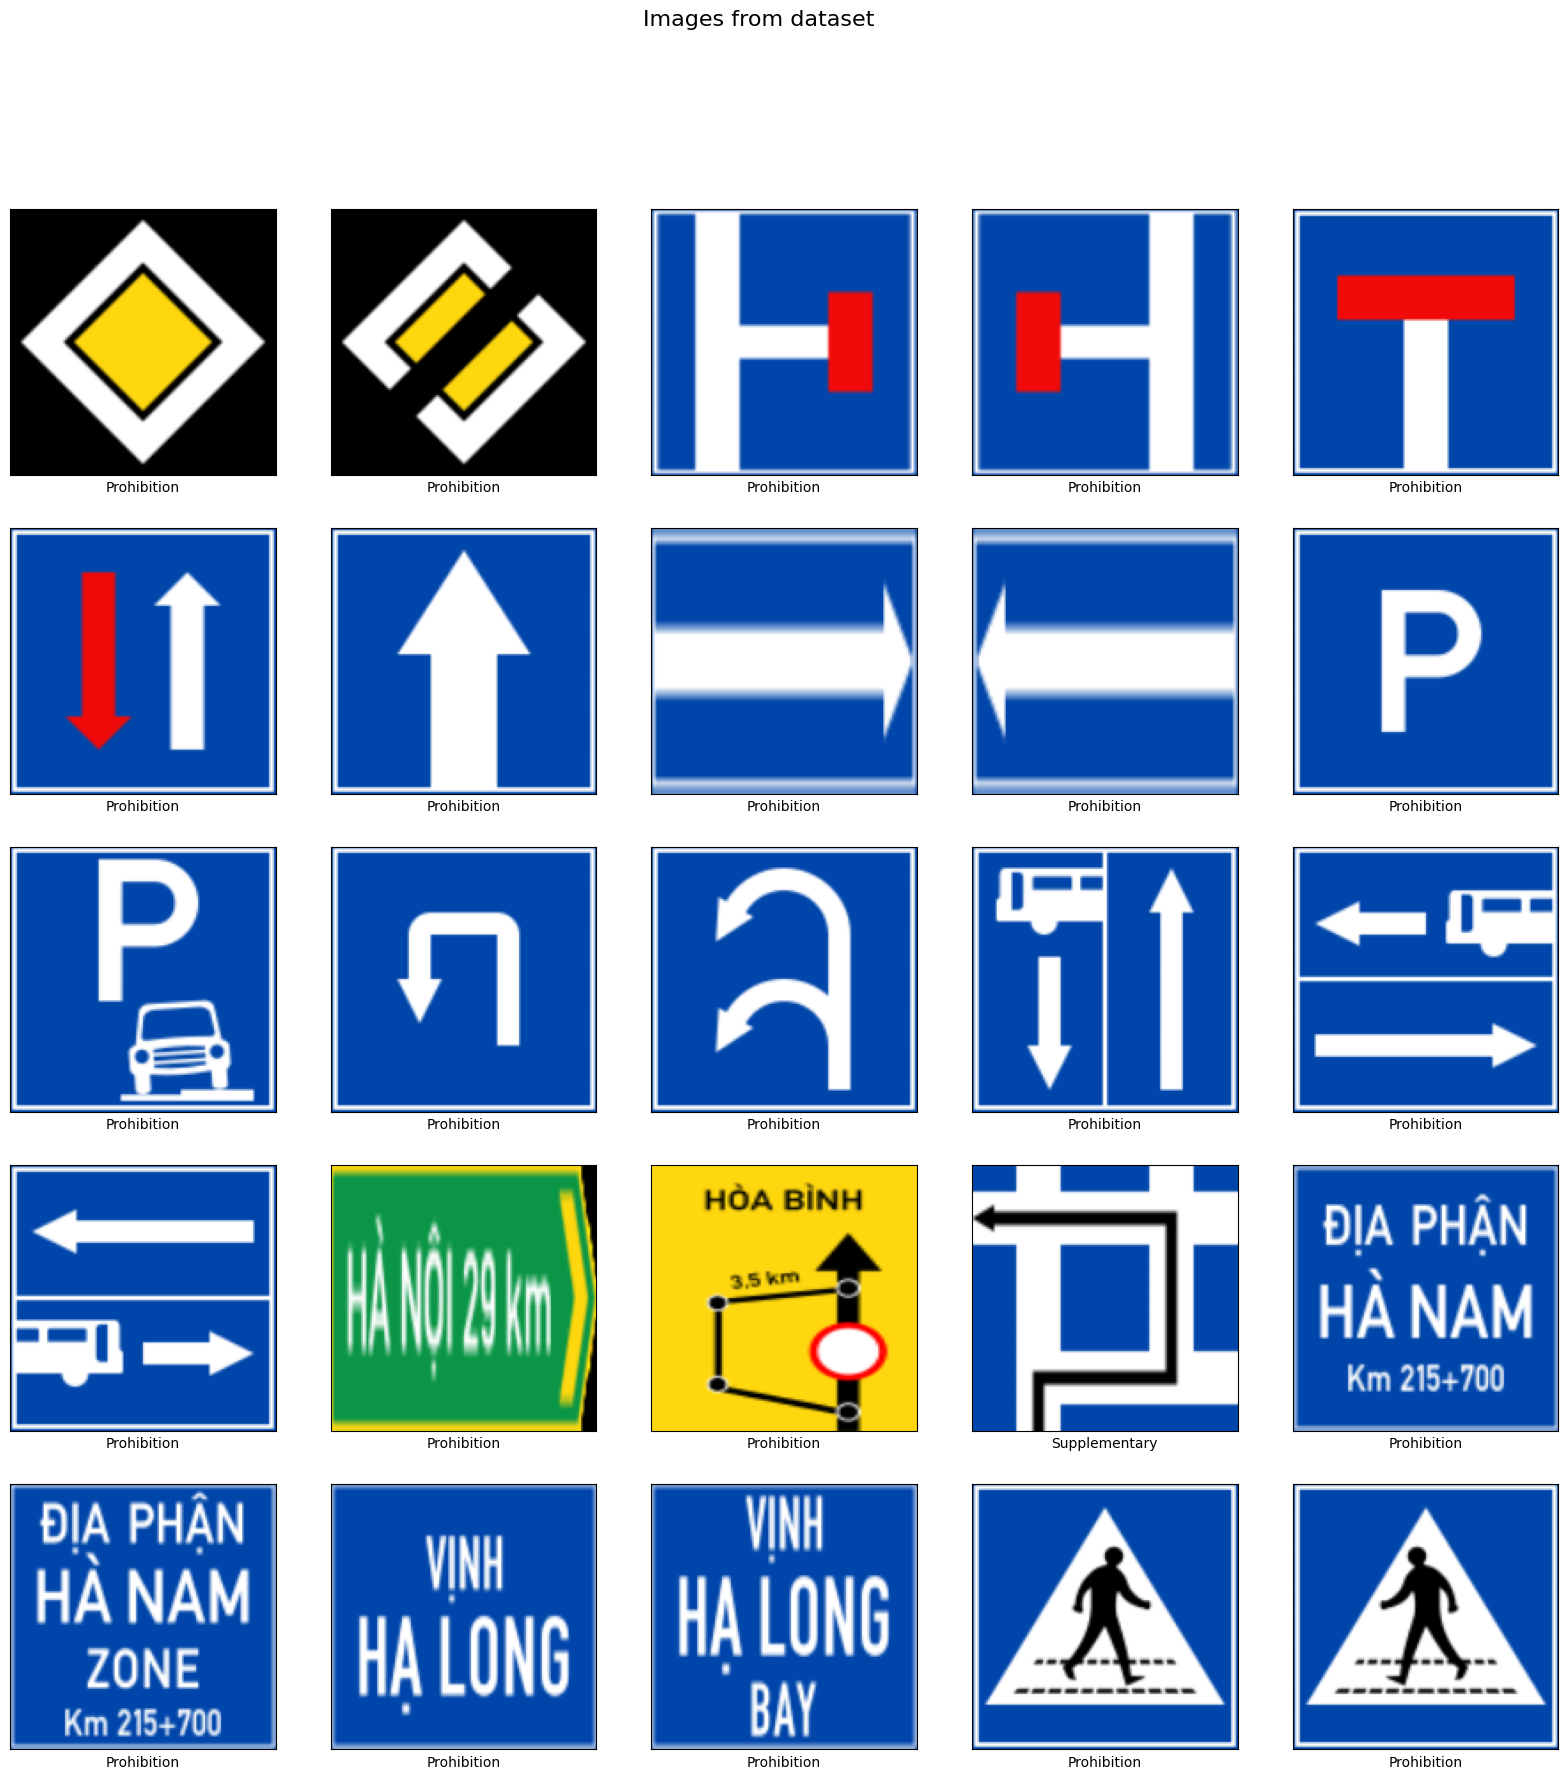

In [3]:
class_names = ['Information', 'Mandatory', 'Prohibition', 'RE', 'Supplementary', 'Warning']
class_names_label = {class_name: i for i, class_name in enumerate(class_names)}
nb_classes = len(class_names)
print(class_names_label)
IMAGE_SIZE = (150, 150)

(train_images, train_labels), (test_images, test_labels) = load_data()
trainn_images, train_labels = shuffle(train_images, train_labels, random_state=25)
display_examples(class_names, train_images, train_labels)